# Texas RMA Longitudinal Geospatial Analysis

This notebook examines synthetic Refugee Medical Assistance enrollment patterns across Texas from FY2019 through FY2024. The analysis focuses on temporal change, geographic expansion, city trajectories, country-of-origin composition, concentration, and ZIP persistence.

All program values are synthetic and intentionally perturbed for portfolio use.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

zip_year = pd.read_csv(ROOT / "data" / "rma_zip_year.csv", dtype={"zip_code": str})
country = pd.read_csv(ROOT / "data" / "rma_zip_country_year.csv", dtype={"zip_code": str})

zip_year.shape, country.shape

((4170, 11), (5691, 6))

## 1. Data overview and quality checks

In [2]:
print("Fiscal years:", sorted(zip_year["fiscal_year"].unique()))
print("Unique ZIP codes:", zip_year["zip_code"].nunique())
print("Complete panel rows:", len(zip_year))
print("Duplicate ZIP-years:", zip_year.duplicated(["fiscal_year", "zip_code"]).sum())
print("Negative enrollment values:", int((zip_year["total_enrollment"] < 0).sum()))
zip_year.head()

Fiscal years: [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
Unique ZIP codes: 695
Complete panel rows: 4170
Duplicate ZIP-years: 0
Negative enrollment values: 0


,fiscal_year,zip_code,city,county,total_enrollment,dominant_country,prior_year_enrollment,yoy_pct,cumulative_enrollment,fy2019_enrollment,change_from_fy2019_pct
0,2019,75001,Addison,Dallas,6,Cuba,NaN,NaN,6,6,0.0
1,2020,75001,Addison,Dallas,16,Cuba,6.0,166.7,22,6,166.7
2,2021,75001,Addison,Dallas,26,Cuba,16.0,62.5,48,6,333.3
3,2022,75001,Addison,Dallas,85,Cuba,26.0,226.9,133,6,1316.7
4,2023,75001,Addison,Dallas,70,Cuba,85.0,-17.6,203,6,1066.7


The ZIP-year table is a complete panel: all 695 ZIP codes appear in all six fiscal years, including zero-enrollment years. Country detail is stored separately in long format and contains only nonzero country counts.

## 2. Statewide longitudinal trend

In [3]:
statewide = (
    zip_year.groupby("fiscal_year", as_index=False)
    .agg(
        total_enrollment=("total_enrollment", "sum"),
        active_zip_codes=("total_enrollment", lambda s: int((s > 0).sum())),
    )
)
active_counties = (
    zip_year[zip_year["total_enrollment"] > 0]
    .groupby("fiscal_year")["county"].nunique()
)
statewide["active_counties"] = statewide["fiscal_year"].map(active_counties)
statewide["yoy_pct"] = statewide["total_enrollment"].pct_change() * 100
statewide.round(1)

,fiscal_year,total_enrollment,active_zip_codes,active_counties,yoy_pct
0,2019,921,196,32,NaN
1,2020,3547,368,46,285.1
2,2021,4243,419,54,19.6
3,2022,13887,529,66,227.3
4,2023,26480,605,79,90.7
5,2024,29892,695,101,12.9


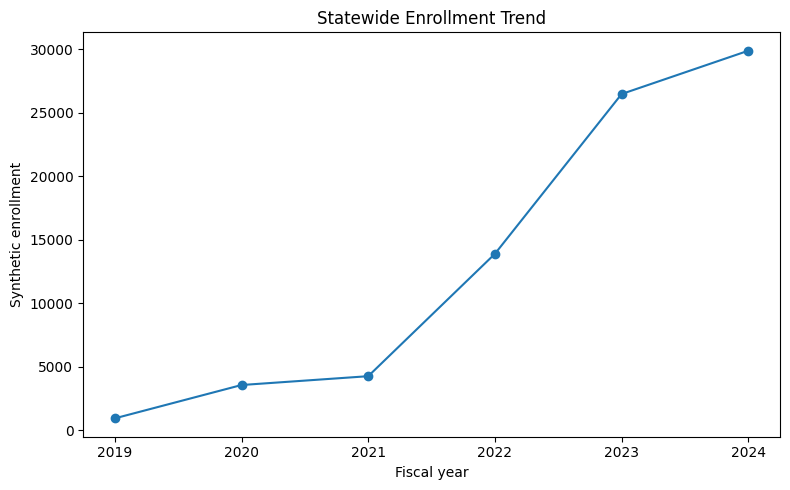

In [4]:
plt.figure(figsize=(8,5))
plt.plot(statewide["fiscal_year"], statewide["total_enrollment"], marker="o")
plt.xlabel("Fiscal year")
plt.ylabel("Synthetic enrollment")
plt.title("Statewide Enrollment Trend")
plt.tight_layout()
plt.show()

## 3. Geographic expansion

In [5]:
fig_data = statewide[["fiscal_year", "active_zip_codes", "active_counties"]]
fig_data

,fiscal_year,active_zip_codes,active_counties
0,2019,196,32
1,2020,368,46
2,2021,419,54
3,2022,529,66
4,2023,605,79
5,2024,695,101


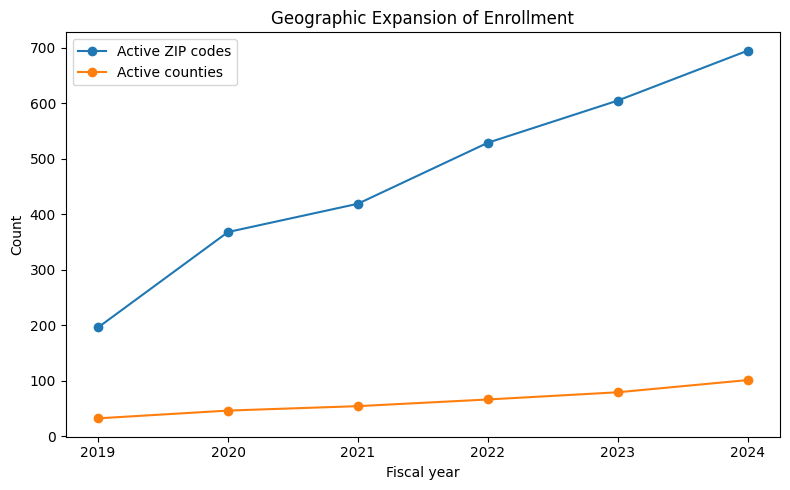

In [6]:
plt.figure(figsize=(8,5))
plt.plot(statewide["fiscal_year"], statewide["active_zip_codes"], marker="o", label="Active ZIP codes")
plt.plot(statewide["fiscal_year"], statewide["active_counties"], marker="o", label="Active counties")
plt.xlabel("Fiscal year")
plt.ylabel("Count")
plt.title("Geographic Expansion of Enrollment")
plt.legend()
plt.tight_layout()
plt.show()

## 4. City-level trajectories

In [7]:
city_year = (
    zip_year.groupby(["fiscal_year", "city"], as_index=False)["total_enrollment"].sum()
)
fy24_top_cities = (
    city_year[city_year["fiscal_year"] == 2024]
    .nlargest(8, "total_enrollment")["city"].tolist()
)
city_pivot = (
    city_year[city_year["city"].isin(fy24_top_cities)]
    .pivot(index="fiscal_year", columns="city", values="total_enrollment")
    .fillna(0)
)
city_pivot

city,Austin,Dallas,Fort Worth,Houston,Irving,Katy,Odessa,San Antonio
fiscal_year,,,,,,,,
2019,97,80,52,389,13,19,18,60
2020,489,223,131,1405,54,90,70,351
2021,410,241,134,1806,66,174,36,359
2022,617,745,483,6217,169,743,410,1209
2023,1297,774,690,11424,231,1545,1245,1826
2024,1721,1171,1066,12754,534,1115,724,2544


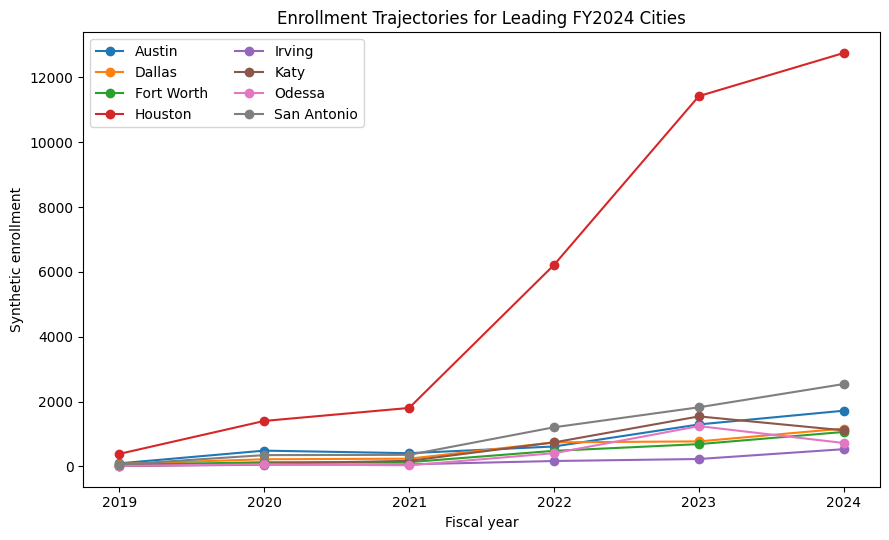

In [8]:
plt.figure(figsize=(9,5.5))
for city_name in city_pivot.columns:
    plt.plot(city_pivot.index, city_pivot[city_name], marker="o", label=city_name)
plt.xlabel("Fiscal year")
plt.ylabel("Synthetic enrollment")
plt.title("Enrollment Trajectories for Leading FY2024 Cities")
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

## 5. Country-of-origin composition

In [9]:
country_year = (
    country.groupby(["fiscal_year", "country"], as_index=False)["enrollment"].sum()
)
top_overall = country.groupby("country")["enrollment"].sum().nlargest(10)
top_overall

country
Cuba                  65222
Afghanistan            5943
Ukraine                1570
Dem. Rep. of Congo     1261
Haiti                  1052
Venezuela               553
Iraq                    331
Burma                   322
Iran                    258
Syria                   258
Name: enrollment, dtype: int64

In [10]:
top_country_names = top_overall.index[:6]
composition = (
    country_year[country_year["country"].isin(top_country_names)]
    .pivot(index="fiscal_year", columns="country", values="enrollment")
    .fillna(0)
)
state_totals = country_year.groupby("fiscal_year")["enrollment"].sum()
composition_share = composition.div(state_totals, axis=0) * 100
composition_share.round(1)

country,Afghanistan,Cuba,Dem. Rep. of Congo,Haiti,Ukraine,Venezuela
fiscal_year,,,,,,
2019,6.4,71.0,4.5,0.0,0.0,2.1
2020,12.5,63.4,3.7,0.1,0.1,3.2
2021,6.4,82.4,2.6,0.4,0.0,0.3
2022,24.7,69.9,1.1,0.1,1.3,0.2
2023,3.2,87.9,1.6,1.1,3.1,0.2
2024,3.0,86.5,1.3,2.4,1.9,1.1


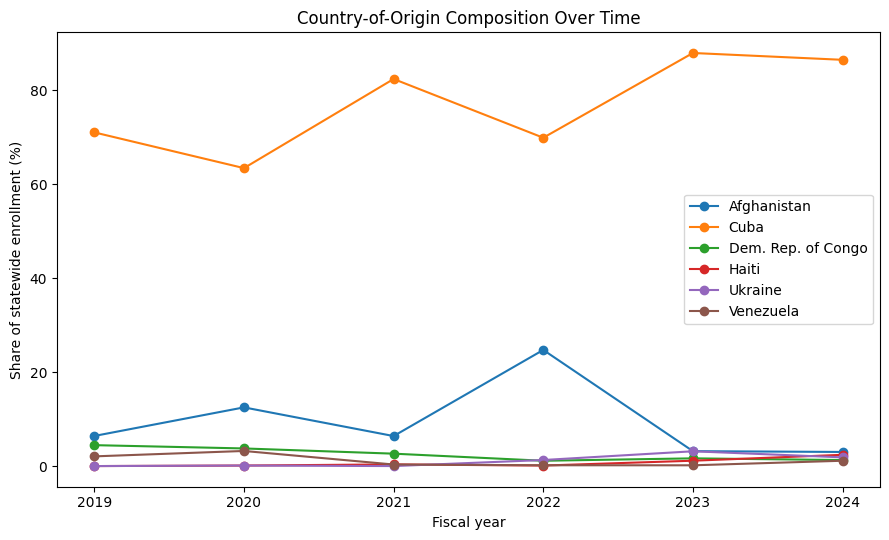

In [11]:
plt.figure(figsize=(9,5.5))
for country_name in composition_share.columns:
    plt.plot(composition_share.index, composition_share[country_name], marker="o", label=country_name)
plt.xlabel("Fiscal year")
plt.ylabel("Share of statewide enrollment (%)")
plt.title("Country-of-Origin Composition Over Time")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Concentration and diversification

In [12]:
def hhi(values):
    values = pd.Series(values)
    shares = values / values.sum()
    return (shares ** 2).sum()

concentration_rows = []
for year, group in country_year.groupby("fiscal_year"):
    ordered = group.sort_values("enrollment", ascending=False)
    total = ordered["enrollment"].sum()
    concentration_rows.append({
        "fiscal_year": year,
        "country_hhi": hhi(ordered["enrollment"]),
        "top_country_share_pct": ordered.iloc[0]["enrollment"] / total * 100,
        "top5_share_pct": ordered.head(5)["enrollment"].sum() / total * 100,
        "countries_with_enrollment": (ordered["enrollment"] > 0).sum(),
    })

concentration = pd.DataFrame(concentration_rows)
concentration.round(3)

,fiscal_year,country_hhi,top_country_share_pct,top5_share_pct,countries_with_enrollment
0,2019,0.513,71.010,86.645,35
1,2020,0.422,63.406,85.114,58
2,2021,0.684,82.371,93.165,41
3,2022,0.550,69.871,97.343,43
4,2023,0.775,87.908,97.009,57
5,2024,0.750,86.455,94.989,56


HHI summarizes concentration across country-of-origin groups. Higher values indicate that statewide enrollment is more concentrated in a smaller number of groups. This is a descriptive composition measure, not a measure of program quality or need.

## 7. ZIP persistence and emergence

In [13]:
active = zip_year[zip_year["total_enrollment"] > 0]
persistence = (
    active.groupby("zip_code", as_index=False)
    .agg(
        city=("city", "first"),
        county=("county", "first"),
        first_active_year=("fiscal_year", "min"),
        years_active=("fiscal_year", "nunique"),
        cumulative_enrollment=("total_enrollment", "sum"),
    )
)
persistence["first_active_year"].value_counts().sort_index()

first_active_year
2019    196
2020    185
2021    108
2022     91
2023     56
2024     59
Name: count, dtype: int64

In [14]:
persistence.nlargest(15, "cumulative_enrollment")

,zip_code,city,county,first_active_year,years_active,cumulative_enrollment
276,77036,Houston,Harris,2019,6,6143
300,77063,Houston,Harris,2019,6,3098
385,77449,Katy,Harris,2019,6,2588
282,77042,Houston,Harris,2019,6,2155
321,77084,Houston,Harris,2019,6,2086
311,77074,Houston,Harris,2019,6,1289
319,77082,Houston,Harris,2019,6,1228
522,78229,San Antonio,Bexar,2019,6,1200
634,78753,Austin,Travis,2019,6,1162
318,77081,Houston,Harris,2019,6,1029


## 8. Recent ZIP-level growth and decline

In [15]:
recent = zip_year[(zip_year["fiscal_year"] == 2024) & zip_year["yoy_pct"].notna()].copy()
recent = recent[recent["prior_year_enrollment"] >= 10]

print("Largest FY2024 increases among ZIPs with FY2023 enrollment >= 10:")
display(recent.nlargest(10, "yoy_pct")[["zip_code","city","county","prior_year_enrollment","total_enrollment","yoy_pct"]])

print("\nLargest FY2024 decreases among ZIPs with FY2023 enrollment >= 10:")
display(recent.nsmallest(10, "yoy_pct")[["zip_code","city","county","prior_year_enrollment","total_enrollment","yoy_pct"]])

Largest FY2024 increases among ZIPs with FY2023 enrollment >= 10:


,zip_code,city,county,prior_year_enrollment,total_enrollment,yoy_pct
1181,76132,Fort Worth,Tarrant,13.0,52,300.0
3839,78759,Austin,Travis,16.0,62,287.5
635,75240,Dallas,Dallas,14.0,53,278.6
155,75050,Grand Prairie,Dallas,11.0,40,263.6
563,75227,Dallas,Dallas,12.0,43,258.3
107,75038,Irving,Dallas,40.0,140,250.0
209,75067,Lewisville,Denton,17.0,59,247.1
911,76014,Arlington,Tarrant,13.0,40,207.7
869,76006,Arlington,Tarrant,16.0,49,206.2
1757,77054,Houston,Harris,11.0,33,200.0



Largest FY2024 decreases among ZIPs with FY2023 enrollment >= 10:


,zip_code,city,county,prior_year_enrollment,total_enrollment,yoy_pct
3413,78504,Mcallen,Hidalgo,29.0,3,-89.7
1277,76210,Corinth,Denton,18.0,2,-88.9
2705,77707,Beaumont,Jefferson,20.0,3,-85.0
215,75068,Little Elm,Denton,21.0,4,-81.0
3527,78621,Elgin,Bastrop,10.0,2,-80.0
2177,77377,Tomball,Harris,29.0,6,-79.3
1991,77094,Houston,Harris,14.0,3,-78.6
1235,76177,Fort Worth,Tarrant,12.0,3,-75.0
2033,77304,Conroe,Montgomery,16.0,4,-75.0
1721,77047,Houston,Harris,38.0,10,-73.7


Filtering out very small prior-year denominators makes the growth ranking easier to interpret. Percentage changes from tiny baselines can otherwise dominate the table without representing the largest absolute program shifts.

## 9. Key findings

In [16]:
fy19 = statewide.loc[statewide["fiscal_year"] == 2019].iloc[0]
fy24 = statewide.loc[statewide["fiscal_year"] == 2024].iloc[0]
overall_growth = (fy24["total_enrollment"] / fy19["total_enrollment"] - 1) * 100

print(f"Statewide enrollment change FY2019→FY2024: {overall_growth:,.1f}%")
print(f"Active ZIP codes FY2019→FY2024: {int(fy19['active_zip_codes'])} → {int(fy24['active_zip_codes'])}")
print(f"Active counties FY2019→FY2024: {int(fy19['active_counties'])} → {int(fy24['active_counties'])}")

fy24_city = city_year[city_year["fiscal_year"] == 2024].nlargest(5, "total_enrollment")
fy24_country = country_year[country_year["fiscal_year"] == 2024].nlargest(5, "enrollment")

display(fy24_city)
display(fy24_country)

Statewide enrollment change FY2019→FY2024: 3,145.6%
Active ZIP codes FY2019→FY2024: 196 → 695
Active counties FY2019→FY2024: 32 → 101


,fiscal_year,city,total_enrollment
1536,2024,Houston,12754
1645,2024,San Antonio,2544
1429,2024,Austin,1721
1476,2024,Dallas,1171
1548,2024,Katy,1115


,fiscal_year,country,enrollment
245,2024,Cuba,25843
234,2024,Afghanistan,898
255,2024,Haiti,716
285,2024,Ukraine,554
246,2024,Dem. Rep. of Congo,383


## 10. Analytical limitations

- All program counts are synthetic and intentionally perturbed for portfolio use.
- The analysis is aggregate and descriptive; it does not identify causal effects.
- ZIP-code geography is a program-analysis unit and should not be interpreted as an individual-level residential history.
- Country composition reflects enrollment counts in the synthetic dataset, not population estimates.
- Year-over-year percentages can be unstable when the prior-year denominator is small.
- Changes in observed enrollment may reflect multiple operational, eligibility, migration, reporting, or policy factors that are not modeled here.